<img src="./logo_UTN.svg" align="right" width="150" /> 

#### Teoría de los Circuitos 2

# **Tarea Semanal 5**
#### Nahuel Siles

Dado el siguiente esquema:

<img src="DiagramaBloques.PNG" />

Se pide:

1. Comprobar que el esquema se corresponde con la siguiente trasnferencia:

$$
H(z) = (1-c_1z^{-N}) \frac { b_0 + b_1 z^{-1} + b_2 z^{-2} }{ \frac{1}{a_0} -  a_1 z^{-1} - a_2 z^{-2} }
$$

2. Filtro de **media móvil** ( moving average ó CIC: cascaded integrator comb )
   - Verificar la transferencia para $a_0=1$, $a_1=1$, $b_0=\frac{1}{N}$, $c_1=1$ y $N=3, 4$ y $5$
   - ¿Es un filtro IIR o FIR? Discuta las ventajas que tendría esta implementación respecto al filtro FIR de media móvil 3.
   - ¿Podría implementar el siguiente sistema $h(k)=(1, 1, 1, 1, 1, 1, 1)$ con esta topología?

3. Filtro **diferenciador** ( differentiator )
   - Obtener los valores de $a_i$  y  $b_k$ para obtener $y(n) = \frac {x(n)-x(n-2) }{2}$
   - Evaluar al sistema con un seno discreto en python y comprobar si la salida se aproxima a la derivada.

4. Filtro **elimina continua** ( DC Blocker)
   - Verificar la transferencia para $a_0=1$, $a_1=\beta$, $b_0=1$ , $b_1=-1$ para $\beta=0.9$
   - Determine $\beta$ para que la transferencia en $\Omega = 0.1\pi$ sea 3dB menor a la transferencia en $\Omega=\pi$

5. Filtro **peine**
   - Verifique la transferencia para $c_1=-1$ y $N=8$
   - Proponga una $f_{sampling}$ y halle las frecuencias donde se generan los peaks y los nulls en el espectro.

Importante: Para los siguientes incisos calcular y representar sus singularidades en el plano  $z$, su Respuesta de módulo y fase de $H(z)$ y su diagrama en bloques. Cuando no se indique considerar los coeficientes igual a cero.

**Bonus**

1. Verificar en Python el punto 3) con la funcion *diff*
2. Utilizando solo el $biquad$, hallar los valores de los coeficientes para emular la respuesta analógica de un pasatodo de orden 1. Utilice alguno de los metodos de diseño vistos en clase.
3. Completar el cuestionario.

### **Módulos de Python**

In [2]:
# Módulos numéricos y de funciones científicas
import numpy as np
from scipy import signal as sig
import sympy as sp
from IPython.display import display, Math

# Módulos para los gráficos
import matplotlib as mpl
from matplotlib import pyplot as plt

# Funciones de PyTC2
from pytc2.sistemas_lineales import bodePlot, pzmap, GroupDelay, analyze_sys, tf2sos_analog, pretty_print_SOS
from pytc2.general import print_latex, print_subtitle, a_equal_b_latex_s

#Tamaño de los gráficos
fig_sz_x = 13
fig_sz_y = 7
fig_dpi = 80 # dpi

fig_font_size = 11

mpl.rcParams['figure.figsize'] = (fig_sz_x, fig_sz_y)
mpl.rcParams['figure.dpi'] = fig_dpi
plt.rcParams.update({'font.size':fig_font_size})

### **Resolución**

#### Expresión del Diagrama de Bloques

Llamamos $u$ al punto siguiente al primer sumador, $v$ al punto entre el segundo sumador y $a_0$ y $w$ al punto medio entre $a_0$ y $b_0$.

Partiendo desde la salida tenemos que:

$$
y(n) = w(n)b_0 + w(n-1)b_1 + w(n-2)b_2
$$

Siendo $w(n) = v(n)a_0 $

La salida del segundo sumador, que es $v$:

$$
v(n) = u(n) + w(n-1)a_1 + w(n-2)a_2
$$

Y la salida de Comb $u$:

$$
u(n) = x(n) - x(n-N)c_1
$$

Para obtener la entrada $x(z)$ reemplazamos $u(n)$ en $v(n)$:

$$
v(n) =  x(n) - x(n-N)c_1 + w(n-1)a_1 + w(n-2)a_2
$$

Y ahora a $w(n)$:

$$
v(n) =  x(n) - x(n-N)c_1 + v(n-1)a_1a_0 + v(n-2)a_2a_0
$$

Aplicando la transformada $z$:

$$
v(z) = x(z) - x(z)z^{-N}c_1 + v(z)z^{-1}a_1a_0 + v(z)z^{-2}a_2a_0
$$

$$
v(z) - v(z)z^{-1}a_1a_0 - v(z)z^{-2}a_2a_0= x(z) - x(z)z^{-N}c_1 
$$

$$
v(z) (1 - z^{-1}a_1a_0 - z^{-2}a_2a_0 )= x(z) (1 - z^{-N}c_1) 
$$

Quedando la entrada $x(z)$:

$$
x(z) = v(z)\frac{1 - z^{-1}a_1a_0 - z^{-2}a_2a_0 }{1 - z^{-N}c_1}
$$

Para obtener la salida $y(z)$ reemplazamos $w(n)$ en $y(n)$:

$$
y(n) = v(n)b_0a_0 + v(n-1)b_1a_0 + v(n-2)b_2a_0
$$

Aplicando la transformada $z$:

$$
y(z) = v(z)b_0a_0 + v(z)z^{-1}b_1a_0 + v(z)z^{-2}b_2a_0
$$

Obtenemos entonces la salida $y(z)$:

$$
y(z) = v(z)( b_0a_0 + z^{-1}b_1a_0 + z^{-2}b_2a_0 )
$$


Para obtener $H(z)$ dividimos $y(z)$ por $x(z)$:

$$
H(z) = \frac{y(z)}{x(z)} = \frac {  v(z)( b_0a_0 + z^{-1}b_1a_0 + z^{-2}b_2a_0 ) } 
                                 { v(z)\frac{1 - z^{-1}a_1a_0 - z^{-2}a_2a_0 }{1 - z^{-N}c_1}}
$$

$$
H(z) = (1 - z^{-N}c_1) \frac { b_0a_0 + z^{-1}b_1a_0 + z^{-2}b_2a_0 } { 1 - z^{-1}a_1a_0 - z^{-2}a_2a_0 }
$$

Comprobamos entonces la transferencia dada:

$$
H(z) = (1 - z^{-N}c_1) \frac { b_0 + z^{-1}b_1 + z^{-2}b_2 } { \frac{1}{a_0} - z^{-1}a_1 - z^{-2}a_2 }
$$


#### **Filtro media móvil**

Reemplazando los coeficientes por los siguientes valores:

$a_0 = a_1 = c_1 = 1$

$b_0 = \frac{1}{N}$

$N = 3, 4, 5$

y considerando al resto igual a cero:

$$
H(z) = (1 - z^{-N}) \frac { \frac{1}{N} } { 1 - z^{-1} }
$$

$$
H(z) = \frac {1 - z^{-N}}{ 1 - z^{-1} } \frac{1}{N}
$$


##### Módulo y Fase

Para obtener el módulo y la fase reemplazamos $z=e^{-j\Omega}$ y operamos:

$$ H(z) = \frac {1 - e^{-j\Omega N}}{ 1 - e^{-j\Omega} } \frac{1}{N} $$

$$
H(z) = \frac { e^{-j\frac{\Omega N}{2}} ( e^{j\frac{\Omega N}{2}} - e^{-j\frac{\Omega N}{2}}) }
                { e^{-j\frac{\Omega}{2}} ( e^{j\frac{\Omega}{2}} - e^{-j\frac{\Omega}{2}}) }
                \frac{1}{N}
$$

$$
H(z) = \frac { e^{-j\frac{\Omega N}{2}} sen(\frac{\Omega N}{2}) }
             { e^{-j\frac{\Omega}{2}}   sen(\frac{\Omega}{2}) }
             \frac{1}{N}
$$

Finalmente:

$$
H(z) = \frac {sen(\frac{\Omega N}{2}) }{ sen(\frac{\Omega}{2}) } \frac{1}{N} e^{j\frac{\Omega}{2}(1-N)}
$$

##### Polos y ceros

Para obtener las singularidades trabajamos la expresión para que nos quede algo conocido:

$$H(z) = \frac {1 - z^{-N}}{ 1 - z^{-1} } \frac{1}{N}$$

$$H(z) = \frac {1 - \frac{1}{z^N}}{ 1 - \frac{1}{z} } \frac{1}{N}$$

$$H(z) = \frac {\frac{z^N - 1}{z^N}}{ \frac{z-1}{z} } \frac{1}{N}$$

$$H(z) = \frac{z^N - 1}{z^N}  \frac{z}{z-1} \frac{1}{N}$$

$$H(z) = \frac{z^N - 1}{z^{N-1}}  \frac{1}{z-1} \frac{1}{N}$$

Siendo la expresión final:

$$H(z) = \frac{z^N - 1}{z^N - z^{N-1} } \frac{1}{N}$$

##### Discretizada

Antitransformando la expresion general:

$$
\frac{y(z)}{x(z)}=\frac {1 - z^{-N}}{ 1 - z^{-1} } \frac{1}{N}
$$

$$
y(z)(1-z^{-1})N = x(z) (1-z^-N)
$$

$$
[y(n)-y(n-1)]N = x(n)-x(n-N)
$$

Obtenemos un **filtro media móvil** para muestras **N**
$$
y(n) = \frac{x(n)-x(n-N)}{N} + y(n-1)
$$

Al depender de la salida anterior a la actual, decimos que es un filtro **IIR**

##### Para N=3

$$H(z) = \frac{z^3 - 1}{z^3 - z^2 } \frac{1}{3}$$

Factorizando:

$$H(z) = \frac{(z-1)(z^2+z+1)}{z^2(z-1)} \frac{1}{3}$$

Entonces:

$$H(z) = \frac{(z^2+z+1)}{z^2} \frac{1}{3}$$

Siendo los polos y ceros:

$p_{1,2}=0$

$z_1=e^{j\frac{2\pi}{3}}$

$z_2=e^{-j\frac{2\pi}{3}}$

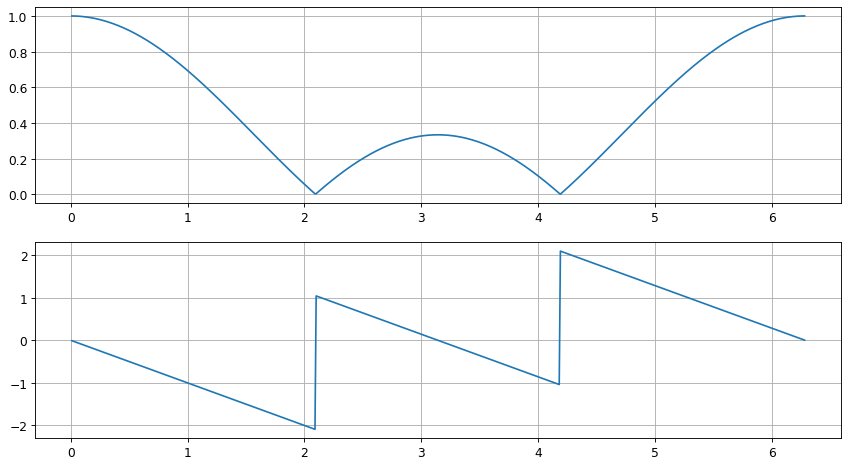

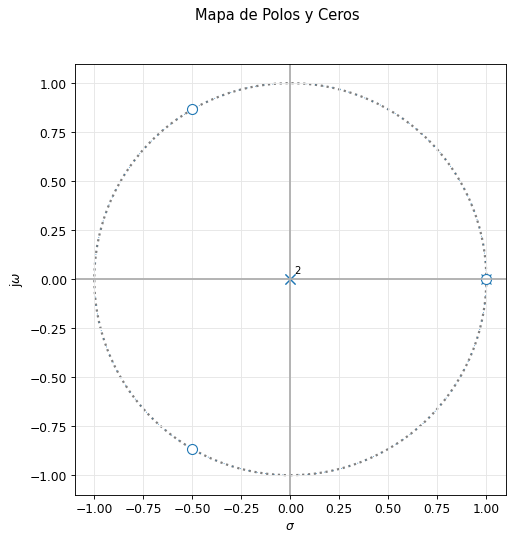

In [5]:
#Variables
pi = np.pi
N=3
w = np.arange(0.01, 2*pi, 0.01)

#Transferencia
H = ( 1 - np.exp(-1j*w*N) ) / ( N*( 1 - np.exp(-1j*w) ) )
num = [1,0,0,-1]
den = [3,-3,0,0]
H2 = sig.TransferFunction(num,den)

#Módulo
Hm = np.abs(H)

#Fase
Hf = np.angle(H)

#Gráficos
plt.subplot(2,1,1)
plt.plot(w,Hm)
plt.grid()

plt.subplot(2,1,2)
plt.plot(w,Hf)
plt.grid()

#Polos y ceros
_=pzmap(H2)

$$ H(z) = \frac {1 - e^{-j\Omega N}}{ 1 - e^{-j\Omega} } \frac{1}{N} $$


##### Para N=4

$$H(z) = \frac{z^4 - 1}{z^4 - z^3 } \frac{1}{4}$$

Factorizando:

$$H(z) = \frac{(z-1)(z+1)(z^2+1)}{z^3( z-1) } \frac{1}{4}$$

Entonces:

$$H(z) = \frac{(z+1)(z^2+1)}{z^3 } \frac{1}{4}$$

Donde los polos y ceros son:

$p_{1,2,3}=0$

$z_1 = -1$

$z_2 = e^{j\frac{\pi}{2}}$

$z_3 = e^{-j\frac{\pi}{2}}$

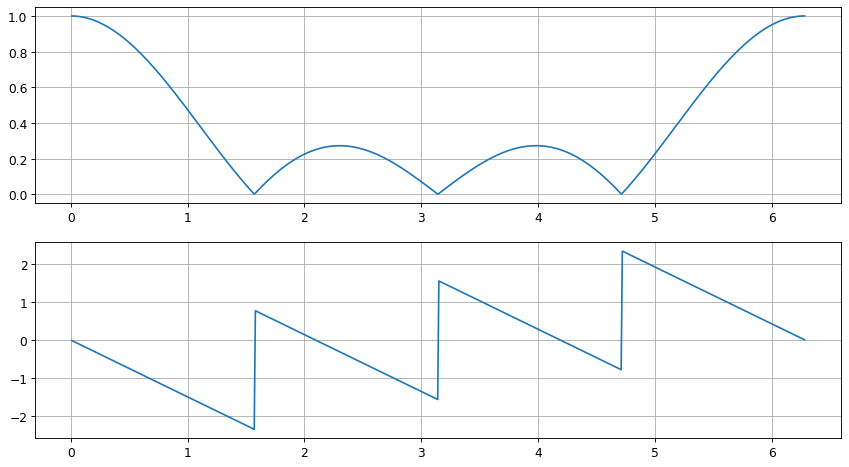

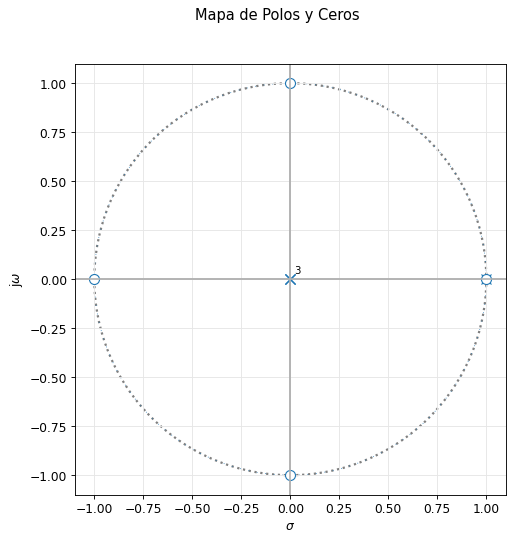

In [4]:
#Variables
pi = np.pi
N=4
w = np.arange(0.01, 2*pi, 0.01)

#Transferencia
H = ( 1 - np.exp(-1j*w*N) ) / ( N*( 1 - np.exp(-1j*w) ) )
num = [1,0,0,0,-1]
den = [4,-4,0,0,0]
H2 = sig.TransferFunction(num,den)

#Módulo
Hm = np.abs(H)

#Fase
Hf = np.angle(H)

#Gráficos
plt.subplot(2,1,1)
plt.plot(w,Hm)
plt.grid()

plt.subplot(2,1,2)
plt.plot(w,Hf)
plt.grid()

#Polos y ceros
_=pzmap(H2)

##### Para N=5

$$H(z) = \frac{z^5 - 1}{z^5 - z^4 } \frac{1}{5}$$

Factorizando:

$$H(z) = \frac{(z-1)(z^4+z^3+z^2+z+1)}{z^4( z-1) } \frac{1}{5}$$

Entonces:

$$H(z) = \frac{(z^4+z^3+z^2+z+1)}{z^4 } \frac{1}{5}$$

Donde los polos y ceros son:

$p_{1,2,3,4}=0$

$z_1 = e^{j\frac{2\pi}{5}}$

$z_2 = e^{-j\frac{2\pi}{5}}$

$z_3 = e^{j\frac{4\pi}{5}}$

$z_4 = e^{-j\frac{4\pi}{5}}$

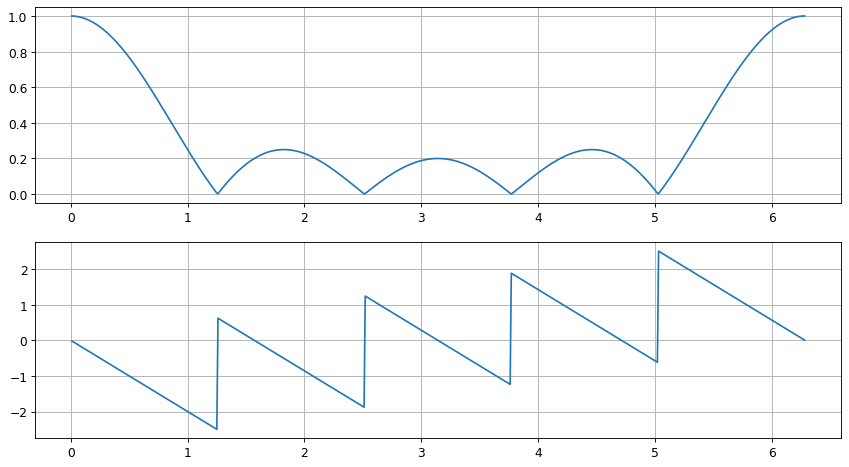

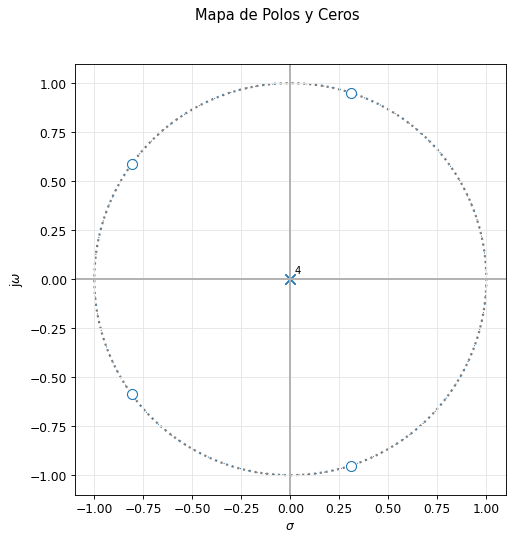

In [3]:
#Variables
pi = np.pi
N=5
w = np.arange(0.01, 2*pi, 0.01)

#Transferencia
H = ( 1 - np.exp(-1j*w*N) ) / ( N*( 1 - np.exp(-1j*w) ) )
num = [1,1,1,1,1]
den = [5,0,0,0,0]
H2 = sig.TransferFunction(num,den)

#Módulo
Hm = np.abs(H)

#Fase
Hf = np.angle(H)

#Gráficos
plt.subplot(2,1,1)
plt.plot(w,Hm)
plt.grid()

plt.subplot(2,1,2)
plt.plot(w,Hf)
plt.grid()

#Polos y ceros
_=pzmap(H2)

#### **Filtro diferenciador**

Para obtener los valores de los coeficientes $a_i$  y  $b_k$ antitransformamos la salida deseada:

$$y(n) = \frac {x(n)-x(n-2) }{2}$$

$$y(z) = \frac{1}{2}x(z) - \frac{1}{2}x(z)z^{-2}$$

Si tenemos:

$$
H(z) = \frac{y(z)}{x(z)} = (1 - z^{-N}c_1) \frac { b_0 + z^{-1}b_1 + z^{-2}b_2 } { \frac{1}{a_0} - z^{-1}a_1 - z^{-2}a_2 }
$$

Asignamos los siguientes valores:

$c_1 = a_1 = a_2 = 0$

$a_0 = 1$

Entonces:

$$\frac{y(z)}{x(z)} =  b_0 + z^{-1}b_1 + z^{-2}b_2 $$

Asignamos:

$b_0 = \frac{1}{2}$

$b_1 = 0$

$b_2 = -\frac{1}{2}$

Por lo que obtenemos un **filtro diferenciador**:

$$\frac{y(z)}{x(z)} =  \frac{1}{2}  - \frac{1}{2} z^{-2} $$

##### Módulo y Fase

Sustituimos $z$ por $e^{j\Omega}$:

$$H(\Omega) = \frac{1}{2}(1-e^{-j2\Omega})$$

$$H(\Omega) = \frac{1}{2} e^{-j\Omega}  (e^{j\Omega}-e^{-j\Omega})$$

$$H(\Omega) = 2j\frac{1}{2} e^{-j\Omega} sen (\Omega)$$

$$H(\Omega) = e^{j\frac{\pi}{2}} e^{-j\Omega} sen (\Omega)$$

Obtenemos entonces:

$$H(\Omega) = sen(\Omega) e^{j (\frac{\pi}{2} - \Omega)  } $$

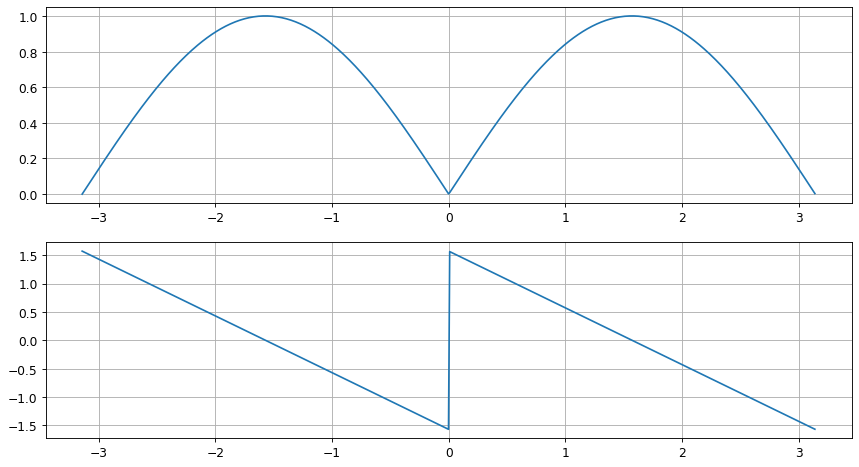

In [40]:
#Variables
pi = np.pi
w = np.arange(-pi, np.pi,0.01)

#Transferencia
H = 1/2 * (1 - np.exp(-1j*2*w) )

#Módulo
Hm = np.abs(H)

#Fase
Hf = np.angle(H)

#Gráficos
plt.subplot(2,1,1)
plt.plot(w,Hm)
plt.grid()

plt.subplot(2,1,2)
plt.plot(w,Hf)
plt.grid()

##### Polos y ceros

Simplificamos la expresión:

$$H(z) = \frac{1}{2}(1-\frac{1}{z^2})$$

$$H(z) = \frac{1}{2}\frac{z^2-1}{z^2}$$

$$H(z) = \frac{z^2-1}{2z^2}$$

Podemos ver a simple vista las singularidades:

$p_{1,2} = 0$

$z_1=1$

$z_2=-1$

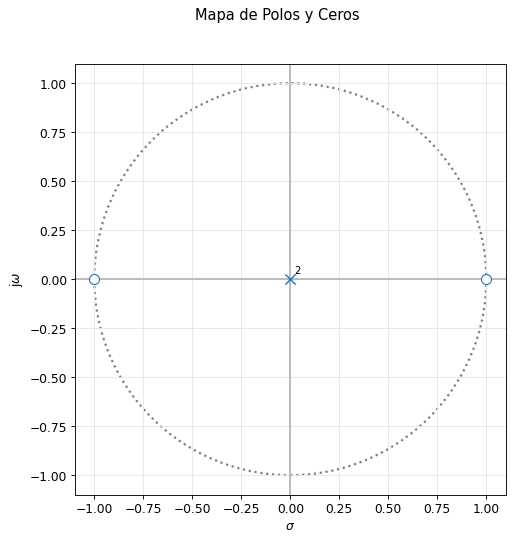

In [36]:
#Transferencia
num = [1,0,-1]
den = [2,0,0]
H = sig.TransferFunction(num,den)

#Polos y ceros
_ = pzmap(H)

##### Evaluación de un seno discreto

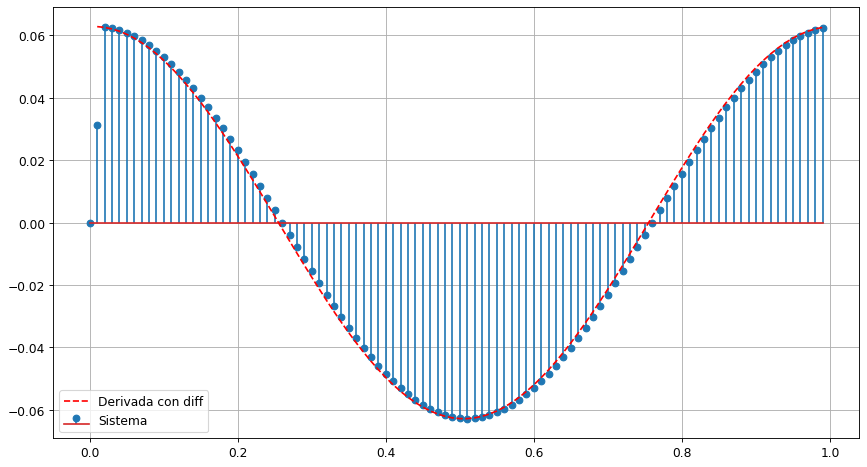

In [9]:
#Variables
w = 2*pi
n = np.arange(0, 1, 0.01)

#Seno discretizado
x = np.sin(w*n)

#Filtro
b = [1/2, 0, -1/2]
a = [1]

#Salida
H = sig.lfilter(b, a, x)
y = np.diff(x)

#Graficos
plt.stem(n, H, label="Sistema")
plt.plot(n[1:], y, "--", color="red", label="Derivada con diff")
plt.legend()
plt.grid()

#### **Filtro elimina continua**

Reemplazamos los valores de los siguientes coeficientes en la transferencia:

$a_0=1$

$a_1=\beta$

$b_0=1$

$b_1=-1$

$\beta=0.9$

Igualando el resto a cero:

$$
H(z) = \frac { 1 - z^{-1} } { 1 - z^{-1}\beta}
$$

En función de la salida y entrada:

$$
\frac{y(z)}{x(z)} = \frac { 1 - z^{-1} } { 1 - z^{-1}\beta}
$$

$$
y(z) (1 - z^{-1}\beta) = x(z) (1 - z^{-1} )
$$


$$
y(z) - y(z)z^{-1}\beta = x(z) - x(z)z^{-1}
$$

Antitransformando:

$$
y(n) - y(n-1)\beta = x(n) - x(n-1)
$$

Obtenemos entonces la expresión de un **filtro elimina continua**

$$
y(n) = x(n) - x(n-1)  + 0.9y(n-1) 
$$

##### Módulo y Fase

Reemplazando $z=e^{j\Omega}$:

$$H(\Omega) = \frac { 1 - e^{-j\Omega} } { 1 - e^{-j\Omega}\beta} $$

$$H(\Omega) = \frac { e^{-j\frac{\Omega}{2}} ( e^{j\frac{\Omega}{2}} - e^{-j\frac{\Omega}{2}}) }
                    { 1 - cos(\Omega)\beta + jsen(\Omega)\beta   } $$

$$H(\Omega) = \frac { 2j e^{-j\frac{\Omega}{2}}   sen(\frac{\Omega}{2}) }
                    { 1 - cos(\Omega)\beta + jsen(\Omega)\beta   } $$

Para el módulo:

$$|H(\Omega)| = \frac { 2 sen(\frac{\Omega}{2}) }
                      { \sqrt{ [1 - cos(\Omega)\beta]^2 + [sen(\Omega)\beta]^2} } $$

$$|H(\Omega)| = \frac { 2 sen(\frac{\Omega}{2}) }
                      { \sqrt{ 1 - 2\beta cos(\Omega) + \beta^2 [ cos^2(\Omega) + sen^2(\Omega) ]} }$$

$$|H(\Omega)| = \frac { 2 sen(\frac{\Omega}{2}) }
                      { \sqrt{ 1 - 2\beta cos(\Omega) + \beta^2 } }$$

Para la fase restamos la del numerador y la del denominador:

$$Num_{fase} = \frac{\pi}{2} - \frac{\Omega}{2}$$

$$Den_{fase} = tg^{-1}( \frac { sen(\Omega)\beta } { 1 - cos(\Omega)\beta } )$$

Entonces:

$$<H(\Omega) = \frac{\pi}{2} - \frac{\Omega}{2} - tg^{-1}( \frac { sen(\Omega)\beta } { 1 - cos(\Omega)\beta } )$$

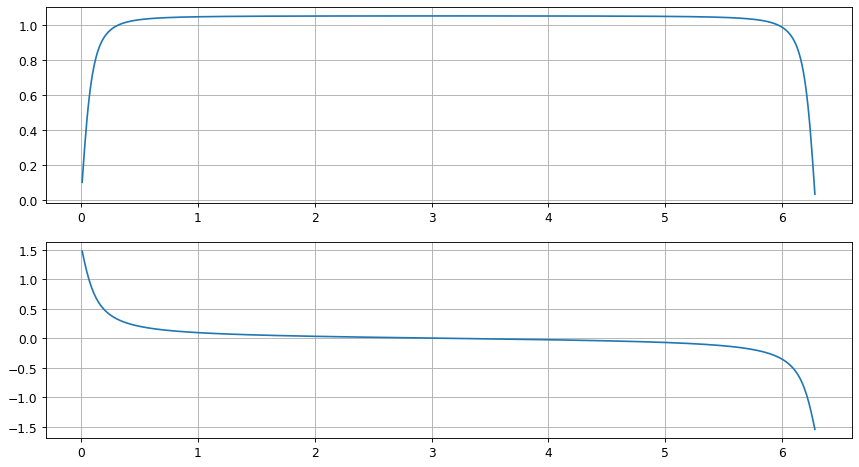

In [37]:
#Variables
pi = np.pi
beta = 0.9
w = np.arange(0.01, 2*pi, 0.01)

#Transferencia
H = ( 1 - np.exp(-1j*w) ) / ( 1 - beta * np.exp(-1j*w) )

#Módulo
Hm = np.abs(H)

#Fase
Hf = np.angle(H)

#Gráficos
plt.subplot(2,1,1)
plt.plot(w,Hm)
plt.grid()

plt.subplot(2,1,2)
plt.plot(w,Hf)
plt.grid()

##### Polos y ceros

Partimos de la expresion de $H(z)$:

$$
H(z) = \frac { 1 - z^{-1} } { 1 - z^{-1}\beta}
$$

Operamos:

$$
H(z) = \frac { 1 - \frac{1} {z} } { 1 - \frac{1} {z}\beta}
$$

$$
H(z) = \frac { \frac{ z-1 } { z } } { \frac{ z - \beta } { z }}
$$

$$
H(z) = \frac{ z-1 } { z } \frac{ z } { z - \beta }
$$

$$
H(z) = \frac{ z-1 } { z - \beta }
$$

Tenemos entonces un polo y un cero:

$p = \beta = 0.9$ (en nuestro inciso)

$z = 1$

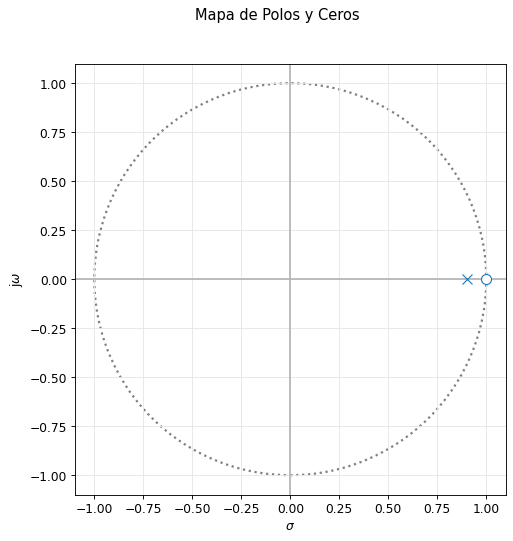

In [32]:
#Variable
beta = 0.9

#Transferencia
num = [1,-1]
den = [1,-beta]

H = sig.TransferFunction(num,den)

#Polos y ceros
_ = pzmap(H)

##### Hallar el valor de $\beta$

PAra hallar el valor de $\beta$ utilizamos la relación que nos dan:

$$\Delta dB = 20log( \frac{ H(0.1\pi) }{ H(\pi) } )$$

$$-3dB = 20log( \frac{ H(0.1\pi) }{ H(\pi) } )$$

$$\frac{-3}{20} = log( \frac{ H(0.1\pi) }{ H(\pi) } )$$

$$10^{ \frac{-3}{20} } = \frac{ H(0.1\pi) }{ H(\pi) } $$

$$10^{ \frac{-3}{20} } = \frac { \frac { 2 sen(\frac{\pi}{2}) }{ \sqrt{ 1 - 2\beta cos(\pi) + \beta^2 } } }
                         {\frac { 2 sen(\frac{0.1\pi}{2}) }{ \sqrt{ 1 - 2\beta cos(0.1\pi) + \beta^2 } } } $$
                            
$$10^{ \frac{-3}{20} } = \frac { \frac { 2 }{ 1 + \beta } }
                         {\frac { 2 sen(\frac{0.1\pi}{2}) }{ \sqrt{ 1 - 2\beta cos(0.1\pi) + \beta^2 } } } $$

$$10^{ \frac{-3}{20} } = \frac { 2 }{ 1 + \beta } 
                         \frac { \sqrt{ 1 - 2\beta cos(0.1\pi) + \beta^2 } }{  2 sen(\frac{0.1\pi}{2}) }  $$


Para facilitar el despeje de $\beta$ utilizamos la librería SymPY de python:

In [94]:
#Frecuencias
w1 = np.pi 
w2 = 0.1*np.pi
#Relacion
A = 10**(-3/20)
#Beta
beta = sp.symbols('beta')

#Modulos evaluados
H1 = ( 2*np.sin(w1/2) ) / ( sp.sqrt( 1-2*beta*np.cos(w1)+beta**2 ) )
H2 = ( 2*np.sin(w2/2) ) / ( sp.sqrt( 1-2*beta*np.cos(w2)+beta**2 ) )

#Ecuacion de igualdad
ecuacion = sp.Eq( H2/H1 , A)

#Resolucion
beta1, beta2 = sp.solve( ecuacion, beta)
print(beta1)
print(beta2)

0.727102581388736
1.37532175733724


Si $\beta > 1$ el polo saldria del circulo unitario, por lo que nos quedamos con $\beta = 0.7271$

In [124]:
#Variables
pi = sp.pi
beta = 0.7271

#Simbolo
w = sp.symbols('w')

#Modulo de transferencia
H = ( 2*sp.sin(w/2) ) / ( sp.sqrt( 1-2*beta*sp.cos(w)+beta**2 ) )

#Evaluacion en las frecuencias dadas
Hm1 = 20*sp.log(H.subs(w, pi), 10 )
Hm2 = 20*sp.log(H.subs(w, 0.1*pi), 10 )

#Muestro
print_latex(a_equal_b_latex_s('H_{dB}(\pi)', Hm1.evalf()))
print_latex(a_equal_b_latex_s('H_{dB}(0.1\pi)', Hm2.evalf()))
print_latex(a_equal_b_latex_s('\Delta dB', Hm2.evalf() - Hm1.evalf()))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### **Filtro peine**

Reemplazamos $c_1 = -1$ y $N=8$ en la transferencia. Esta vez consideramos el resto de coeficientes iguales a cero salvo $b_0$ y $a_0$ que los igualamos a 1.

$$
H(z) = (1 + z^{-8}1)
$$

Antitransformando:

$$
\frac{y(z)}{x(z)} = (1 + z^{-8}1)
$$


$$
y(z) = x(z) + x(z)z^{-8}
$$

Entonces queda la expresión de un **filtro peine**:

$$y(n) = x(n) + x(n-8)$$

##### Módulo y Fase

Para obtener el módulo reemplazamos $z=e^{j\Omega}$

$$H(\Omega) = 1 + e^{-j8\Omega}$$

$$H(\Omega) = e^{-j4\Omega}( e^{j4\Omega} + e^{-j4\Omega} )$$

$$H(\Omega) =  e^{-j4\Omega}( 2cos(4\Omega) )$$

Entonces:

$$H(\Omega) =  2cos(4\Omega) e^{-j4\Omega}$$

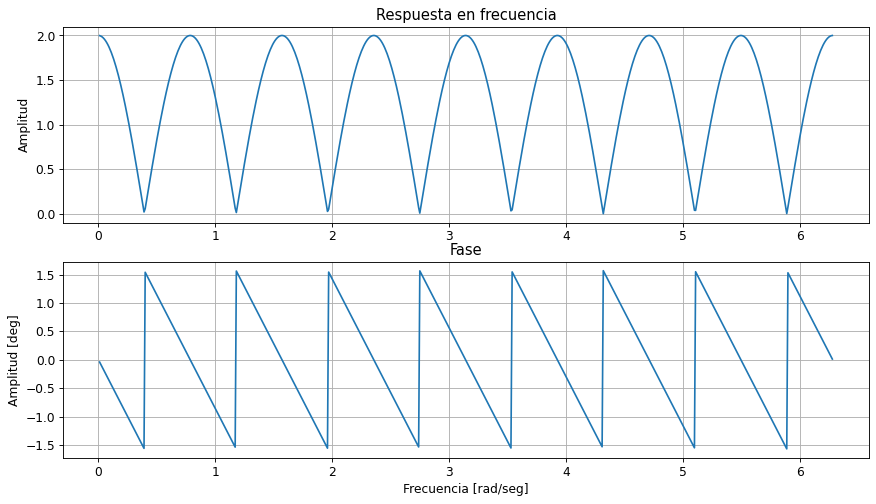

In [6]:
#Variables
pi = np.pi
w = np.arange(0.01, 2*pi, 0.01)

#Transferencia
H = 1 + np.exp( -1j*8*w )

#Módulo
Hm = np.abs(H)
#hm = np.abs( 2*np.cos(4*w) )

#Fase
Hf = np.angle(H)

#Gráficos
plt.subplot(2,1,1)
plt.plot(w,Hm)
#plt.plot(w,hm,"--")
plt.title('Respuesta en frecuencia')
plt.ylabel('Amplitud')
plt.grid()

plt.subplot(2,1,2)
plt.plot(w,Hf)
plt.title('Fase')
plt.xlabel('Frecuencia [rad/seg]')
plt.ylabel('Amplitud [deg]')
plt.grid()

##### Polos y ceros

Obtener las singularidades es sencillo:

$$H(z) = 1 + z^{-8} $$

$$H(z) = 1 +  \frac { 1 } { z^8 } $$

$$H(z) = \frac { z^8 + 1 } { z^8 } $$

Vemos que tenemos:

$p_{1,2,3,4,5,6,7,8} = 0$

Para los ceros:

$$z^8 = -1$$

$$z = (-1)^{ \frac{1}{8} }$$

$$z = (j)^{ \frac{1}{8} }$$

$$z = (e^{j (\pi+2k\pi) } )^{ \frac{1}{8} }$$

$$z = (e^{j \pi(1+2k) } )^{ \frac{1}{8} }$$

$$z = e^{j \frac { \pi(1+2k) } {8} } $$

Entonces:

$z_{1,8} = +- \frac {\pi} {8}$

$z_{2,7} = +- \frac {3\pi} {8}$

$z_{3,6} = +- \frac {5\pi} {8}$

$z_{4,5} = +- \frac {7\pi} {8}$

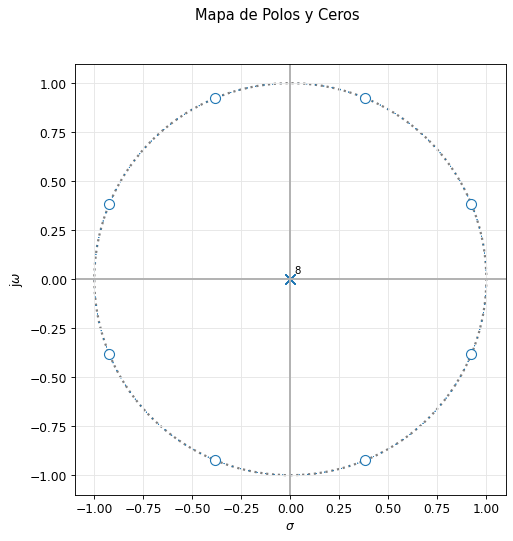

In [46]:
#Coeficientes
num = [1,0,0,0,0,0,0,0,1]
den = [1,0,0,0,0,0,0,0,0]

#Transferencia
H = sig.TransferFunction(num,den)

#Polos y ceros
_ = pzmap(H)

##### Ubicación de los peaks y nulls

Para la ubicación de los peaks tenemos en cuenta el valor maximo que puede tomar em módulo de la transferencia:

$$|H(\Omega)| =  |2cos(4\Omega)|$$

La función se hace máxima cuando $cos(\theta) = 1$ o $-1$, es decir, cuando $\theta = 0$ o multiplos enteros de $\pi$:

$$4\Omega = k*\pi$$

$$\Omega = \frac{k*\pi}{4}$$

En términos de $f$:

$$2\pi f_{max} = \frac{k*\pi}{4}$$

$$f_{max} = \frac{k*\pi}{2\pi*4}$$

$$f_{max} = \frac{k}{8}$$

Si normalizamos por una frecuencia de muestreo $f_s$:

$$\frac{f_{max}}{f_s} = \frac{k}{8}$$

$$f_{max} = \frac{k*fs}{8}$$



Ahora para obtener los nulls necesitamos que $cos(\theta) = 0$, es decir, cuando $\theta = \frac{\pi}{2}$ o multiplos enteros de $\frac{\pi}{2}$:

$$4\Omega = \pi \frac{2k + 1}{2}$$

$$\Omega = (2k + 1) \frac{\pi}{4*2}$$

$$\Omega = (2k + 1) \frac{\pi}{8}$$

En términos de $f$ y normalizada por $f_s$:


$$\frac{2\pi f_{mim}}{f_s} = (2k + 1) \frac{\pi}{8}$$

$$\frac{f_{mim}}{f_s} = (2k + 1) \frac{\pi}{2 \pi 8}$$

$$f_{mim} = (2k + 1) \frac{fs}{16}$$

C:\Users\ASUS\AppData\Local\Temp\ipykernel_8984\2949071004.py:12: RuntimeWarning: divide by zero encountered in log10
  modh = 20*np.log10(np.abs(h))


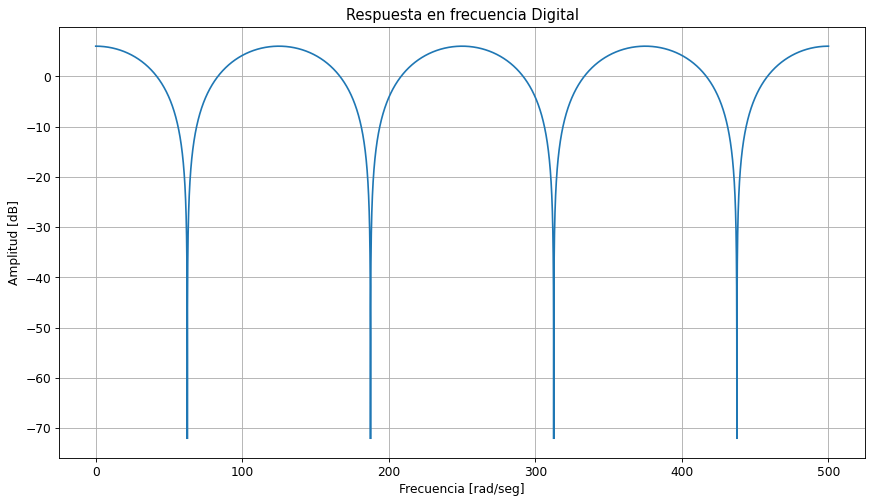

In [81]:
#Coeficientes
num = [1,0,0,0,0,0,0,0,1]
den = [1]

#Parametros Digitales
fs = 1000
wN = fs/2
npoints = 100000

#Respuesta digital
w, h = sig.freqz(num, den, npoints, fs=fs)
modh = 20*np.log10(np.abs(h))

plt.figure()
plt.plot(w,modh)
plt.title('Respuesta en frecuencia Digital')
plt.xlabel('Frecuencia [rad/seg]')
plt.ylabel('Amplitud [dB]')
plt.grid()